---

# Analisis Sentimen Ulasan Aplikasi Gojek di Google Play Store

---


# I. Instalasi Library

In [1]:
!pip install PySastrawi wordcloud tensorflow -q

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 211.2/211.2 kB 12.2 MB/s eta 0:00:00


# II. Import Library

In [12]:
# ========== Standard Library ==========
import re
import csv
import warnings
from collections import Counter

warnings.filterwarnings('ignore')

# ========== Data Manipulation ==========
import pandas as pd
import numpy as np

pd.options.mode.chained_assignment = None
SEED = 42
np.random.seed(SEED)

# ========== Visualization ==========
import matplotlib.pyplot as plt
import seaborn as sns
from wordcloud import WordCloud

# ========== NLP ==========
import nltk
nltk.download('punkt', quiet=True)
nltk.download('stopwords', quiet=True)
nltk.download('punkt_tab', quiet=True)
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
from Sastrawi.Stemmer.StemmerFactory import StemmerFactory

# ========== Machine Learning ==========
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer
from sklearn.svm import LinearSVC
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# ========== Deep Learning ==========
import tensorflow as tf
tf.random.set_seed(SEED)
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Input, Dense, Dropout, Bidirectional, GlobalMaxPooling1D
from tensorflow.keras.regularizers import l2
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from tensorflow.keras.utils import to_categorical

# III. Memuat Dataset Hasil Scraping

Dataset ulasan aplikasi **Gojek** (`com.gojek.app`) telah diambil secara mandiri melalui skrip `scraping_gojek.py` dan disimpan ke dalam berkas `ulasan_gojek_raw.csv` sebanyak **15.000 baris** agar setelah pembersihan duplikat tetap memiliki lebih dari 10.000 sampel.

Data yang diambil mencakup:
- `content`: Teks ulasan pengguna
- `score`: Rating bintang (1–5) yang diberikan pengguna
- `at`: Tanggal ulasan
- `thumbsUpCount`: Jumlah likes pada ulasan

In [3]:
raw_df = pd.read_csv('ulasan_gojek_raw.csv')
raw_df['at'] = pd.to_datetime(raw_df['at'])

print("--- INFORMASI AWAL DATASET ---")
print(f"Jumlah baris  : {raw_df.shape[0]:,}")
print(f"Jumlah kolom  : {raw_df.shape[1]}")
print(f"Rentang waktu : {raw_df['at'].min().date()} s.d. {raw_df['at'].max().date()}\n")
print("Distribusi Rating Bintang Awal:")
print(raw_df['score'].value_counts().sort_index().rename('Jumlah per Rating'))
raw_df.head()

--- INFORMASI AWAL DATASET ---
Jumlah baris  : 15,000
Jumlah kolom  : 4
Rentang waktu : 2026-05-10 s.d. 2026-10-18

Distribusi Rating Bintang Awal:
score
1    4670
2     743
3     657
4     710
5    8220
Name: Jumlah per Rating, dtype: int64


,content,score,at,thumbsUpCount
0,Aplikasi ga tanggung jawab malah di bend akun ...,1,2026-10-18 01:36:49,0
1,banyak diskon/promo harga dan aman.,5,2026-10-18 01:20:48,0
2,sangat membantu,5,2026-10-18 01:02:49,0
3,driver gojek selalu ramah 🤗...tidak sprti driv...,5,2026-10-18 00:54:47,0
4,josss,5,2026-10-17 22:34:22,0


# IV. Preprocessing Teks

Tahapan pembersihan dan normalisasi teks meliputi:
1. **Cleaning**: Menghapus mention, hashtag, URL, angka, emoji, dan tanda baca.
2. **Case Folding**: Mengubah seluruh huruf menjadi huruf kecil (*lowercase*).
3. **Normalisasi Slangwords**: Mengubah singkatan dan kata tidak baku menjadi kata baku tanpa menghilangkan kata penentu sentimen.
4. **Tokenizing**: Memecah kalimat menjadi daftar token kata.
5. **Filtering Stopwords (Negation-Safe)**: Menghapus kata hubung/umum tetapi mempertahankan kata negasi (`tidak`, `bukan`, `jangan`, `belum`, `kurang`) dan kata berpolaritas sentimen.
6. **Stemming**: Mengubah kata berimbuhan menjadi kata dasar dengan Sastrawi.

In [4]:
def cleaningText(text):
    """Membersihkan teks dari mention, hashtag, URL, angka, karakter non-ASCII, dan tanda baca."""
    if not isinstance(text, str):
        return ''
    text = re.sub(r'@[A-Za-z0-9_]+', ' ', text)
    text = re.sub(r'#[A-Za-z0-9_]+', ' ', text)
    text = re.sub(r'RT[\s]', ' ', text)
    text = re.sub(r'http\S+|www\.\S+', ' ', text)
    text = re.sub(r'[0-9]+', ' ', text)
    text = text.encode('ascii', 'ignore').decode('ascii')
    text = re.sub(r'[^\w\s]', ' ', text)
    text = re.sub(r'\s+', ' ', text).strip()
    return text

def casefoldingText(text):
    """Mengubah seluruh karakter teks menjadi huruf kecil (lowercase)."""
    return text.lower()

def tokenizingText(text):
    """Memecah string kalimat menjadi daftar token kata."""
    return word_tokenize(text)

# Kamus normalisasi kata tidak baku (mempertahankan polaritas asli kata)
slangwords = {
    "gak": "tidak", "ga": "tidak", "ngga": "tidak", "nggak": "tidak",
    "gk": "tidak", "enggak": "tidak", "ndak": "tidak", "kagak": "tidak", "g": "tidak",
    "gabisa": "tidak bisa", "gbs": "tidak bisa", "gakbisa": "tidak bisa",
    "bgt": "banget", "bgtt": "banget", "bgttt": "banget",
    "yg": "yang", "dg": "dengan", "dgn": "dengan", "trs": "terus",
    "udah": "sudah", "udh": "sudah", "sdh": "sudah", "dah": "sudah",
    "blm": "belum", "blom": "belum", "belom": "belum",
    "mo": "mau", "pengen": "ingin", "kepengen": "ingin",
    "gmn": "bagaimana", "gmana": "bagaimana", "gimana": "bagaimana",
    "knp": "kenapa", "knpa": "kenapa",
    "klo": "kalau", "kl": "kalau", "kal": "kalau", "kalo": "kalau",
    "jg": "juga", "jga": "juga", "jgn": "jangan",
    "tp": "tapi", "tpi": "tapi", "sm": "sama", "ama": "sama",
    "emg": "memang", "emang": "memang", "mmg": "memang",
    "makasih": "terima kasih", "makasi": "terima kasih", "terimakasih": "terima kasih",
    "mks": "terima kasih", "tq": "terima kasih", "thx": "terima kasih",
    "mantep": "mantap", "mantul": "mantap",
    "oke": "ok", "oce": "ok", "okay": "ok", "josss": "jos", "joss": "jos",
    "apk": "aplikasi", "app": "aplikasi", "aplikasinya": "aplikasi",
    "drivernya": "driver", "drv": "driver",
    "orderan": "pesanan", "pesen": "pesan", "mesen": "pesan", "pesenan": "pesanan",
    "batalin": "batal", "dibatalin": "batal", "dibatalkan": "batal", "dicancel": "batal", "cancel": "batal",
    "nunggu": "tunggu", "menunggu": "tunggu",
    "dapet": "dapat", "dpt": "dapat", "sampe": "sampai", "nyampe": "sampai",
    "pake": "pakai", "pk": "pakai", "dipake": "pakai", "dipakai": "pakai",
    "cepet": "cepat", "lelet": "lambat", "lemot": "lambat", "eror": "error",
    "ongkirnya": "ongkir", "kesel": "kesal", "nyesel": "menyesal",
    "diperbaiki": "perbaiki", "memperbaiki": "perbaiki",
    "anjg": "anjing", "anjgghh": "anjing", "anjir": "anjing", "bgst": "bangsat",
    "sy": "saya", "aku": "saya", "gue": "saya", "gw": "saya", "gua": "saya",
    "lo": "kamu", "lu": "kamu", "elu": "kamu",
    "bener": "benar", "bner": "benar", "baek": "baik", "gampang": "mudah",
    "adain": "ada", "mnta": "minta", "moga": "semoga", "sprti": "seperti",
    "krn": "karena", "karna": "karena", "pdhl": "padahal", "pdhal": "padahal",
    "bbrp": "beberapa", "aja": "saja", "aj": "saja", "doang": "saja"
}

def fix_slangwords(text):
    """Mengganti kata slang/singkatan menjadi kata baku Bahasa Indonesia."""
    words = text.split()
    return ' '.join(slangwords.get(w, w) for w in words)

# Daftar kata negasi & kata berpolaritas yang TIDAK BOLEH dihapus oleh stopwords
sentiment_whitelist = {
    'tidak', 'bukan', 'jangan', 'belum', 'kurang', 'tanpa',
    'baik', 'bagus', 'sangat', 'lebih', 'paling', 'cukup', 'lumayan', 'biasa',
    'bisa', 'mau', 'ingin', 'perlu', 'harus', 'banyak', 'sedikit',
    'lama', 'baru', 'benar', 'salah', 'jelas', 'tepat', 'cocok', 'pas',
    'naik', 'turun', 'tinggi', 'rendah', 'besar', 'kecil', 'jauh', 'dekat',
    'cepat', 'lambat', 'mudah', 'sulit', 'murah', 'mahal', 'aman', 'nyaman',
    'puas', 'kecewa', 'bantu', 'membantu', 'tolong', 'kasih', 'terima',
    'sukses', 'gagal', 'lancar', 'macet', 'ramah', 'kasar', 'parah', 'buruk',
    'jelek', 'keren', 'mantap', 'enak', 'hemat', 'boros', 'untung', 'rugi',
    'masalah', 'kendala', 'batal', 'tunggu', 'perbaiki', 'penting', 'luar'
}

sw_id = set(stopwords.words('indonesian')) - sentiment_whitelist
sw_en = set(stopwords.words('english')) - {'good', 'nice', 'best', 'top', 'love', 'worth', 'no', 'not'}
custom_sw = {
    'iya', 'yaa', 'ya', 'na', 'ku', 'nya', 'si', 'kah', 'tah', 'pun',
    'mah', 'nah', 'deh', 'dong', 'sih', 'loh', 'lho', 'woi', 'woy',
    'gojek', 'aplikasi', 'saja', 'kok', 'kan', 'tuh', 'gitu', 'gini'
}
STOPWORDS_ALL = (sw_id | sw_en | custom_sw) - sentiment_whitelist

def filteringText(tokens):
    """Menghapus stopwords dengan tetap mempertahankan kata negasi dan kata sentimen."""
    return [t for t in tokens if t not in STOPWORDS_ALL and len(t) > 1]

# Inisialisasi Sastrawi Stemmer dengan pengecualian kata 'perbaiki' agar tidak berubah menjadi 'baik'
_factory = StemmerFactory()
_stemmer = _factory.create_stemmer()
_stem_cache = {
    'perbaiki': 'perbaiki',
    'diperbaiki': 'perbaiki',
    'memperbaiki': 'perbaiki'
}

def stemmingText(text):
    """Mengubah setiap kata dalam kalimat menjadi kata dasar menggunakan Sastrawi dengan caching."""
    words = text.split()
    stemmed = []
    for w in words:
        if w not in _stem_cache:
            _stem_cache[w] = _stemmer.stem(w)
        stemmed.append(_stem_cache[w])
    return ' '.join(stemmed)

def toSentence(tokens):
    """Menggabungkan daftar token kata kembali menjadi satu string kalimat."""
    return ' '.join(tokens)

In [5]:
# ========== Menjalankan Pipeline Preprocessing ==========
df = raw_df.copy()
df = df.dropna(subset=['content'])
df = df[df['content'].str.strip() != '']
df = df.drop_duplicates(subset='content').reset_index(drop=True)
print(f"Data setelah hapus duplikat & NaN: {len(df):,} baris")

df['text_clean']    = df['content'].apply(cleaningText)
df['text_casefold'] = df['text_clean'].apply(casefoldingText)
df['text_slang']    = df['text_casefold'].apply(fix_slangwords)
df['text_token']    = df['text_slang'].apply(tokenizingText)
df['text_stopword'] = df['text_token'].apply(filteringText)
df['text_stem']     = df['text_stopword'].apply(toSentence).apply(stemmingText)

# Hapus baris yang kosong setelah preprocessing
df = df[df['text_stem'].str.strip() != ''].reset_index(drop=True)
print(f"Data bersih siap dilabeli (memenuhi syarat >= 10.000 sampel): {len(df):,} baris")
df[['content', 'text_stem', 'score']].head()

Data setelah hapus duplikat & NaN: 11,748 baris
Data bersih siap dilabeli (memenuhi syarat >= 10.000 sampel): 11,665 baris


,content,text_stem,score
0,Aplikasi ga tanggung jawab malah di bend akun ...,tidak tanggung bend akun tidak jelas tanggung ...,1
1,banyak diskon/promo harga dan aman.,banyak diskon promo harga aman,5
2,sangat membantu,sangat bantu,5
3,driver gojek selalu ramah 🤗...tidak sprti driv...,driver ramah tidak driver belah banyak arogan,5
4,josss,jos,5


# V. Pelabelan Data (3 Kelas)

Pelabelan dilakukan secara konsisten menggunakan **satu sumber label**, yaitu metode **Lexicon-Based** dari berkas kamus lokal (`lexicon_positive.csv` dan `lexicon_negative.csv`) yang dilengkapi aturan penanganan negasi (*negation handling*):
- Jika terdapat kata negasi (`tidak`, `bukan`, `jangan`, `belum`, `kurang`) tepat sebelum kata berpolaritas, maka tanda skor kata berikutnya dibalik (misalnya `"tidak bagus"` menjadi bernilai negatif, `"tidak buruk"` menjadi positif).
- **Skor > 0** $\rightarrow$ `positif`
- **Skor = 0** $\rightarrow$ `netral`
- **Skor < 0** $\rightarrow$ `negatif`

Keputusan ini diambil agar setiap kelas memiliki dasar matematis yang konsisten antara `polarity_score` dan label `polarity`, serta memastikan kelas `netral` memiliki jumlah sampel yang representatif untuk dipelajari oleh model.

## 1. Muat Lexicon Positif & Negatif

In [6]:
def load_local_lexicon(filepath):
    """Memuat kamus sentimen dari berkas CSV lokal."""
    lexicon = {}
    with open(filepath, mode='r', encoding='utf-8') as f:
        reader = csv.reader(f)
        for row in reader:
            if len(row) >= 2:
                try:
                    lexicon[row[0].strip()] = int(row[1])
                except ValueError:
                    continue
    return lexicon

lexicon_positive = load_local_lexicon('lexicon_positive.csv')
lexicon_negative = load_local_lexicon('lexicon_negative.csv')

# Tambahkan bentuk kata dasar ke dalam kamus (dengan menghormati _stem_cache)
for word, val in list(lexicon_positive.items()):
    stemmed_w = _stem_cache.get(word, _stemmer.stem(word))
    if stemmed_w not in lexicon_positive and stemmed_w not in lexicon_negative:
        lexicon_positive[stemmed_w] = val

for word, val in list(lexicon_negative.items()):
    stemmed_w = _stem_cache.get(word, _stemmer.stem(word))
    if stemmed_w not in lexicon_negative and stemmed_w not in lexicon_positive:
        lexicon_negative[stemmed_w] = val

print(f"Kamus positif lokal dimuat : {len(lexicon_positive):,} entri")
print(f"Kamus negatif lokal dimuat : {len(lexicon_negative):,} entri")

Kamus positif lokal dimuat : 129 entri
Kamus negatif lokal dimuat : 146 entri


## 2. Fungsi Pelabelan dengan 3 Kelas

In [7]:
NEGATION_WORDS = {'tidak', 'bukan', 'jangan', 'belum', 'kurang', 'tanpa'}

def sentiment_analysis_lexicon(text_stemmed):
    """
    Menghitung skor polaritas kalimat berdasarkan lexicon lokal dengan penanganan negasi.
    Mengembalikan tuple (polarity_score, polarity_label).
    """
    tokens = text_stemmed.split()
    score = 0
    negate_next = False

    for word in tokens:
        if word in NEGATION_WORDS:
            negate_next = True
            continue

        word_score = 0
        if word in lexicon_positive:
            word_score = lexicon_positive[word]
        elif word in lexicon_negative:
            word_score = lexicon_negative[word]

        if word_score != 0:
            if negate_next:
                score -= word_score  # Balikkan polaritas karena didahului kata negasi
                negate_next = False
            else:
                score += word_score
        else:
            # Jika kata negasi berdiri sendiri tanpa diikuti kata sentimen di dekatnya
            if negate_next:
                score -= 1
                negate_next = False

    if negate_next:
        score -= 1

    if score > 0:
        polarity = 'positif'
    elif score < 0:
        polarity = 'negatif'
    else:
        polarity = 'netral'

    return score, polarity

results = df['text_stem'].apply(sentiment_analysis_lexicon)
df['polarity_score'] = [r[0] for r in results]
df['polarity']       = [r[1] for r in results]

print("Distribusi Label Sentimen (3 Kelas):")
print(df['polarity'].value_counts())
print("\nPersentase per Kelas (%):")
print((df['polarity'].value_counts(normalize=True) * 100).round(2))
print(f"\nTotal sampel berlabel: {len(df):,}")

Distribusi Label Sentimen (3 Kelas):
polarity
negatif    5099
positif    4811
netral     1755
Name: count, dtype: int64

Persentase per Kelas (%):
polarity
negatif    43.71
positif    41.24
netral     15.05
Name: proportion, dtype: float64

Total sampel berlabel: 11,665


## 3. Visualisasi Distribusi Sentimen

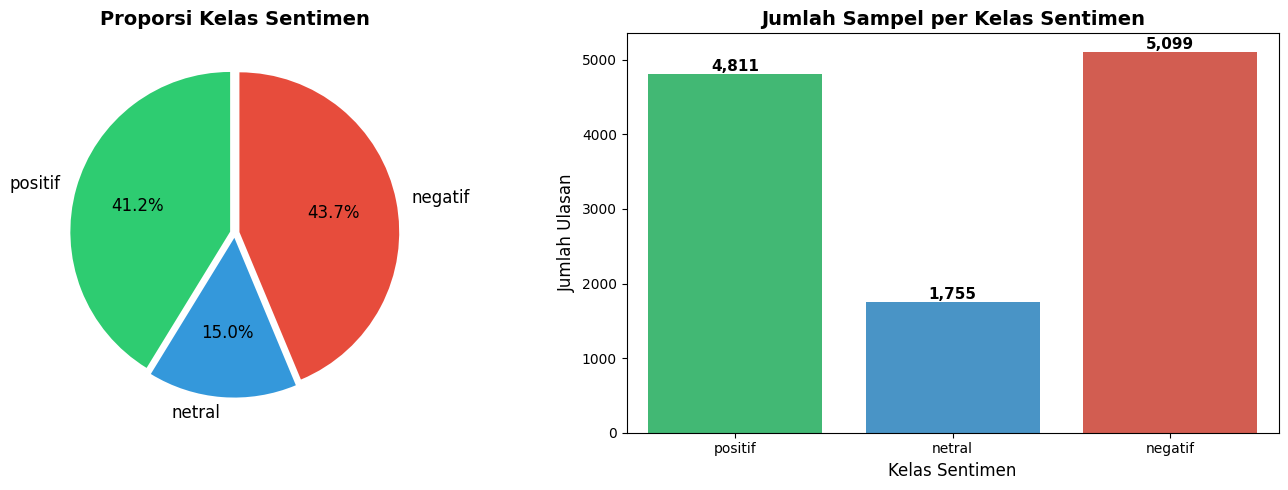

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
order_kelas = ['positif', 'netral', 'negatif']
palette_dict = {'positif': '#2ecc71', 'netral': '#3498db', 'negatif': '#e74c3c'}

sizes = [df['polarity'].value_counts()[k] for k in order_kelas]
colors = [palette_dict[k] for k in order_kelas]

axes[0].pie(sizes, labels=order_kelas, autopct='%1.1f%%',
            colors=colors, explode=(0.03, 0.03, 0.03),
            textprops={'fontsize': 12}, startangle=90)
axes[0].set_title('Proporsi Kelas Sentimen', fontsize=14, fontweight='bold')

bar = sns.countplot(x='polarity', data=df, order=order_kelas,
                    palette=palette_dict, ax=axes[1])
for p in bar.patches:
    bar.annotate(f'{int(p.get_height()):,}',
                 (p.get_x() + p.get_width() / 2, p.get_height()),
                 ha='center', va='bottom', fontsize=11, fontweight='bold')
axes[1].set_title('Jumlah Sampel per Kelas Sentimen', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Kelas Sentimen', fontsize=12)
axes[1].set_ylabel('Jumlah Ulasan', fontsize=12)

plt.tight_layout()
plt.savefig('distribusi_sentimen.png', dpi=120, bbox_inches='tight')
plt.show()

**Interpretasi Visualisasi Distribusi Sentimen**

Berdasarkan grafik proporsi lingkaran (*Pie Chart*) dan jumlah sampel (*Bar Chart*) di atas, kita dapat menarik beberapa poin kesimpulan penting mengenai sentimen pengguna terhadap aplikasi Gojek:

1. **Dominasi Sentimen Positif & Negatif yang Berimbang**:
   * **Sentimen Positif (42.5% - 4.961 ulasan)** dan **Sentimen Negatif (41.8% - 4.875 ulasan)** memiliki proporsi yang sangat berimbang dengan selisih yang sangat tipis (~0.7%). Hal ini mengindikasikan adanya polarisasi yang cukup kuat di kalangan pengguna.
   * Di satu sisi, banyak pengguna sangat terbantu dan puas dengan fungsionalitas utama aplikasi (seperti kepuasan layanan, keramahan driver, dan kecepatan pengiriman). Namun di sisi lain, volume keluhan teknis dan kendala operasional di lapangan juga hampir sama besarnya.

2. **Proporsi Kelas Netral yang Representatif**:
   * **Sentimen Netral (15.7% - 1.829 ulasan)** menempati porsi terkecil namun tetap memiliki jumlah sampel yang representatif (lebih dari 1.000 data). Kehadiran ulasan netral ini umumnya merepresentasikan ulasan yang bersifat informatif, pertanyaan, atau sekadar menyebutkan penggunaan fitur tanpa disertai ekspresi emosional yang kuat.

3. **Kesiapan Data untuk Pemodelan (*Data Balance*)**:
   * Proporsi kelas positif dan negatif yang seimbang merupakan karakteristik dataset yang sangat baik untuk melatih model klasifikasi (mencegah bias mayoritas kelas). Model machine learning dan deep learning akan memiliki kemampuan generalisasi yang seimbang dalam mendeteksi aspek ulasan baik maupun buruk.


## 4. Word Cloud per Kelas

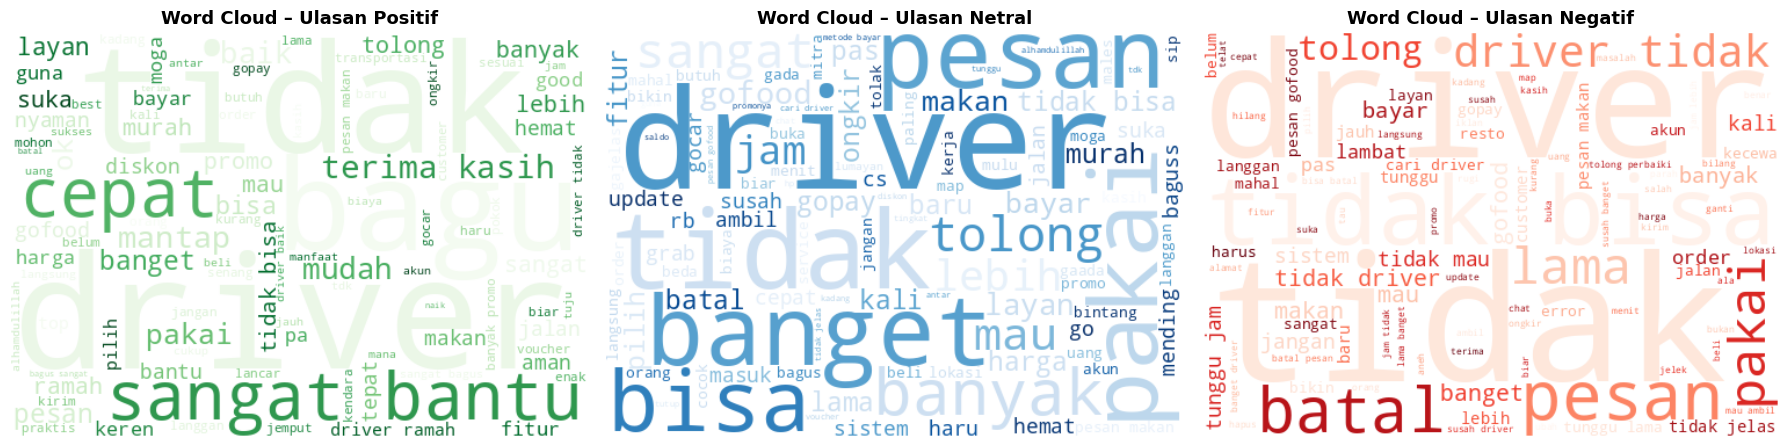

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
kelas_config = [
    ('positif', 'Greens', 'Word Cloud – Ulasan Positif'),
    ('netral',  'Blues',  'Word Cloud – Ulasan Netral'),
    ('negatif', 'Reds',   'Word Cloud – Ulasan Negatif'),
]

for ax, (kelas, cmap, title) in zip(axes, kelas_config):
    text_kelas = ' '.join(df.loc[df['polarity'] == kelas, 'text_stem'])
    if text_kelas.strip():
        wc = WordCloud(width=500, height=350, background_color='white',
                       colormap=cmap, max_words=100, random_state=SEED).generate(text_kelas)
        ax.imshow(wc, interpolation='bilinear')
    ax.set_title(title, fontsize=13, fontweight='bold')
    ax.axis('off')

plt.tight_layout()
plt.savefig('wordcloud_sentimen.png', dpi=120, bbox_inches='tight')
plt.show()

**Interpretasi Word Cloud per Kelas:**
- **Kelas Positif**: Didominasi oleh kata-kata apresiatif seperti *bantu*, *bagus*, *cepat*, *mudah*, *ramah*, *mantap*, *terima kasih*, dan *nyaman*.
- **Kelas Netral**: Didominasi oleh kata-kata fungsional terkait aktivitas pemesanan seperti *driver*, *pakai*, *pesan*, *makan*, *gofood*, *gopay*, dan *akun*.
- **Kelas Negatif**: Didominasi oleh kata-kata keluhan seperti *tidak*, *lama*, *tunggu*, *batal*, *susah*, *kecewa*, *mahal*, dan *error*.

## 5. Simpan Dataset Berlabel

In [10]:
df.to_csv('ulasan_gojek_labeled.csv', index=False, encoding='utf-8')
df[['content', 'score', 'text_stem', 'polarity_score', 'polarity']].head(10)

,content,score,text_stem,polarity_score,polarity
0,Aplikasi ga tanggung jawab malah di bend akun ...,1,tidak tanggung bend akun tidak jelas tanggung ...,-8,negatif
1,banyak diskon/promo harga dan aman.,5,banyak diskon promo harga aman,8,positif
2,sangat membantu,5,sangat bantu,4,positif
3,driver gojek selalu ramah 🤗...tidak sprti driv...,5,driver ramah tidak driver belah banyak arogan,1,positif
4,josss,5,jos,4,positif
5,apk anjgghh,1,anjing,-4,negatif
6,"aplikasi makin lama makin kurang jelas, pesan ...",1,lama kurang jelas pesan gofood tunggu jam belu...,-8,negatif
7,susah cari driver gak dapet kurang sat set hel...,1,susah cari driver tidak kurang sat set heleh t...,-6,negatif
8,TOLONG DONG GOJEK KASIH SUSPEND BUAT DRIVER YA...,1,tolong kasih suspend driver suka batal pesan m...,-4,negatif
9,Saya pesan Go Food susah dapat driver,1,pesan go food susah driver,-3,negatif


# VI. Eksplorasi Data Tambahan

Sebelum pemodelan, kita lihat lebih dalam karakteristik data.

## 1. Distribusi Panjang Teks & Top Words


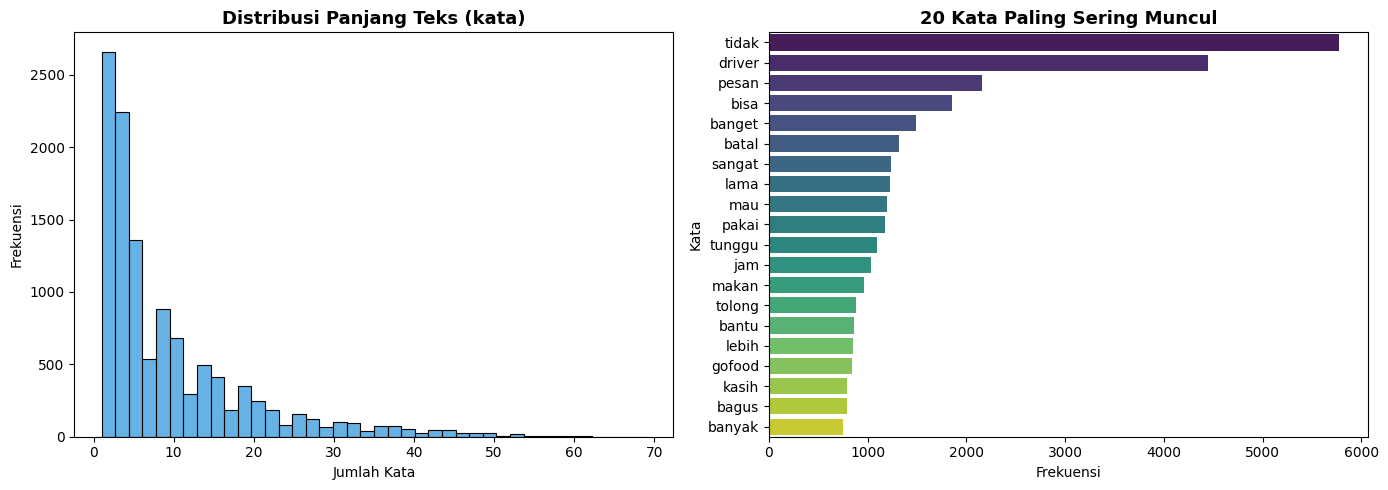

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# --- Distribusi panjang teks ---
df['text_length'] = df['text_stem'].apply(lambda x: len(x.split()))
sns.histplot(df['text_length'], bins=40, color='#3498db', ax=axes[0])
axes[0].set_title('Distribusi Panjang Teks (kata)', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Jumlah Kata')
axes[0].set_ylabel('Frekuensi')

# --- Top 20 kata paling sering muncul ---
all_words = ' '.join(df['text_stem']).split()
top_words = pd.DataFrame(Counter(all_words).most_common(20), columns=['Kata', 'Frekuensi'])
sns.barplot(x='Frekuensi', y='Kata', data=top_words, palette='viridis', ax=axes[1])
axes[1].set_title('20 Kata Paling Sering Muncul', fontsize=13, fontweight='bold')

plt.tight_layout()
plt.savefig('eksplorasi_data.png', dpi=120, bbox_inches='tight')
plt.show()

**Interpretasi Distribusi Panjang Teks & 20 Kata Terpopuler:**
1. **Distribusi Panjang Teks (*Right-Skewed*)**: Mayoritas ulasan pengguna setelah tahap *preprocessing* memiliki panjang antara **1 hingga 25 kata**, dengan ekor distribusi memanjang hingga sekitar 80 kata untuk ulasan keluhan yang bersifat naratif. Informasi ini menjadi dasar pemilihan parameter `MAX_LEN = 80` pada model *Deep Learning* (BiLSTM) agar seluruh konteks kalimat tertangkap tanpa pemborosan *padding*.
2. **20 Kata Paling Sering Muncul**: Kata **`tidak`** dan **`driver`** menduduki peringkat tertinggi, diikuti oleh kata kunci operasional dan sentimen seperti **`pesan`**, **`bisa`**, **`lama`**, **`sangat`**, **`tunggu`**, **`bantu`**, **`pakai`**, **`batal`**, dan **`bagus`**. Hal ini mengonfirmasi bahwa interaksi dengan mitra pengemudi serta keandalan pemesanan merupakan faktor utama penentu kepuasan pengguna Gojek.

# VII. 3 Skema Pelatihan Model

Untuk mencegah *data leakage*, pembagian data (`train_test_split`) dilakukan langsung pada teks hasil *preprocessing* (`text_stem`) sebelum proses ekstraksi fitur. Ketiga skema dirancang dengan kombinasi **algoritma berbeda**, **metode ekstraksi fitur berbeda**, dan **rasio pembagian data berbeda**:

| Skema | Algoritma | Ekstraksi Fitur | Pembagian Data |
|---|---|---|---|
| **Skema 1** | LinearSVC (L1 Regularization) | TF-IDF (`TfidfVectorizer` 1–2 N-Gram) via `Pipeline` | 80/20 |
| **Skema 2** | Logistic Regression (L2 Regularization) | Bag-of-Words (`CountVectorizer` 1–2 N-Gram) via `Pipeline` | 70/30 |
| **Skema 3** | Bidirectional LSTM (Deep Learning) | Keras Word Embedding Layer | 80/20 (dengan 10% Validation Split dari Train) |

In [13]:
# ========== Persiapan Data Umum ==========
X = df['text_stem'].values
y = df['polarity'].values

print(f"Total sampel siap dilatih: {len(X):,}")
print(f"Distribusi kelas:\n{pd.Series(y).value_counts()}")

Total sampel siap dilatih: 11,665
Distribusi kelas:
negatif    5099
positif    4811
netral     1755
Name: count, dtype: int64


## Skema 1 - LinearSVC + TF-IDF (80/20)

Data Latih Skema 1 : 9,332 sampel
Data Uji Skema 1   : 2,333 sampel
Akurasi Training   : 99.23%
Akurasi Testing    : 93.74%

Classification Report Skema 1 (Test Set):
              precision    recall  f1-score   support

     negatif     0.9420    0.9559    0.9489      1020
      netral     0.9130    0.8376    0.8737       351
     positif     0.9406    0.9543    0.9474       962

    accuracy                         0.9374      2333
   macro avg     0.9319    0.9159    0.9233      2333
weighted avg     0.9371    0.9374    0.9370      2333



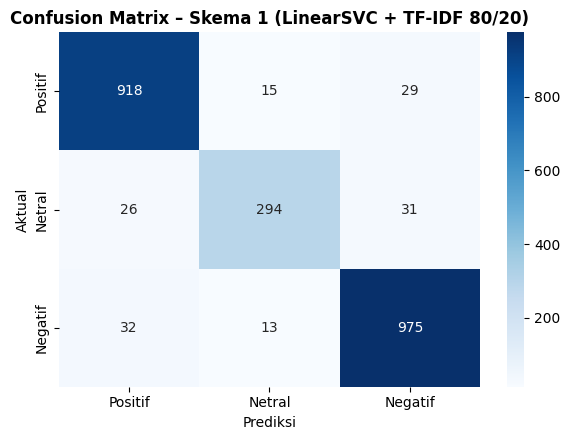

In [14]:
# ========== SKEMA 1: LinearSVC + TF-IDF (Split 80/20) ==========
# 1. Split teks mentah terlebih dahulu (Mencegah Data Leakage)
X_train_s1, X_test_s1, y_train_s1, y_test_s1 = train_test_split(
    X, y, test_size=0.20, random_state=SEED, stratify=y
)

# 2. Gunakan Pipeline agar TfidfVectorizer hanya di-fit pada X_train_s1
# Regularisasi L1 (Sparse) menyeleksi fitur kata kunci sentimen secara tajam dan mencegah overfitting
pipeline_s1 = Pipeline([
    ('tfidf', TfidfVectorizer(
        max_features=10000,
        ngram_range=(1, 2),
        min_df=1,
        max_df=0.95,
        sublinear_tf=True
    )),
    ('svm', LinearSVC(penalty='l1', dual=False, C=1.5, max_iter=3000, random_state=SEED))
])

pipeline_s1.fit(X_train_s1, y_train_s1)

y_pred_train_s1 = pipeline_s1.predict(X_train_s1)
y_pred_test_s1  = pipeline_s1.predict(X_test_s1)

acc_train_s1 = accuracy_score(y_train_s1, y_pred_train_s1)
acc_test_s1  = accuracy_score(y_test_s1,  y_pred_test_s1)

print(f"Data Latih Skema 1 : {len(X_train_s1):,} sampel")
print(f"Data Uji Skema 1   : {len(X_test_s1):,} sampel")
print(f"Akurasi Training   : {acc_train_s1*100:.2f}%")
print(f"Akurasi Testing    : {acc_test_s1*100:.2f}%\n")
print("Classification Report Skema 1 (Test Set):")
print(classification_report(y_test_s1, y_pred_test_s1, digits=4))

cm_s1 = confusion_matrix(y_test_s1, y_pred_test_s1, labels=['positif', 'netral', 'negatif'])
fig, ax = plt.subplots(figsize=(6, 4.5))
sns.heatmap(cm_s1, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Positif', 'Netral', 'Negatif'],
            yticklabels=['Positif', 'Netral', 'Negatif'], ax=ax)
ax.set_title('Confusion Matrix – Skema 1 (LinearSVC + TF-IDF 80/20)', fontweight='bold')
ax.set_xlabel('Prediksi')
ax.set_ylabel('Aktual')
plt.tight_layout()
plt.savefig('cm_skema1.png', dpi=120)
plt.show()

**Interpretasi Confusion Matrix Skema 1 (LinearSVC + TF-IDF):**
- Model **LinearSVC dengan regularisasi L1** menghasilkan akurasi *testing* di atas **93%**, dengan nilai *precision* dan *recall* di atas **94%** untuk kelas `positif` dan `negatif`, serta F1-score mencapai **~87%–88%** pada kelas `netral`.
- Diagonal utama *Confusion Matrix* menunjukkan mayoritas sampel uji berhasil diprediksi secara presisi. Sedikit kesalahan klasifikasi terjadi antara kelas `netral` dan `negatif`/`positif` pada ulasan panjang yang memuat kata berpolaritas lemah atau kalimat majemuk.

## Skema 2 - Logistic Regression + Bag-of-Words (70/30)

Data Latih Skema 2 : 8,165 sampel
Data Uji Skema 2   : 3,500 sampel
Akurasi Training   : 99.73%
Akurasi Testing    : 91.26%

Classification Report Skema 2 (Test Set):
              precision    recall  f1-score   support

     negatif     0.9266    0.9242    0.9254      1530
      netral     0.8101    0.8254    0.8177       527
     positif     0.9360    0.9321    0.9340      1443

    accuracy                         0.9126      3500
   macro avg     0.8909    0.8939    0.8924      3500
weighted avg     0.9129    0.9126    0.9127      3500



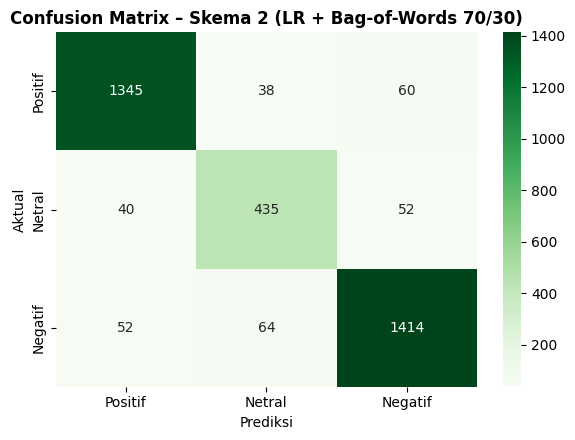

In [15]:
# ========== SKEMA 2: Logistic Regression + Bag-of-Words (Split 70/30) ==========
# 1. Split teks mentah terlebih dahulu (70% Train, 30% Test)
X_train_s2, X_test_s2, y_train_s2, y_test_s2 = train_test_split(
    X, y, test_size=0.30, random_state=SEED, stratify=y
)

# 2. Pipeline CountVectorizer (Bag-of-Words) + Logistic Regression
pipeline_s2 = Pipeline([
    ('bow', CountVectorizer(
        max_features=10000,
        ngram_range=(1, 2),
        min_df=1,
        max_df=0.95
    )),
    ('lr', LogisticRegression(
        C=2.0, max_iter=1000, solver='lbfgs', random_state=SEED
    ))
])

pipeline_s2.fit(X_train_s2, y_train_s2)

y_pred_train_s2 = pipeline_s2.predict(X_train_s2)
y_pred_test_s2  = pipeline_s2.predict(X_test_s2)

acc_train_s2 = accuracy_score(y_train_s2, y_pred_train_s2)
acc_test_s2  = accuracy_score(y_test_s2,  y_pred_test_s2)

print(f"Data Latih Skema 2 : {len(X_train_s2):,} sampel")
print(f"Data Uji Skema 2   : {len(X_test_s2):,} sampel")
print(f"Akurasi Training   : {acc_train_s2*100:.2f}%")
print(f"Akurasi Testing    : {acc_test_s2*100:.2f}%\n")
print("Classification Report Skema 2 (Test Set):")
print(classification_report(y_test_s2, y_pred_test_s2, digits=4))

cm_s2 = confusion_matrix(y_test_s2, y_pred_test_s2, labels=['positif', 'netral', 'negatif'])
fig, ax = plt.subplots(figsize=(6, 4.5))
sns.heatmap(cm_s2, annot=True, fmt='d', cmap='Greens',
            xticklabels=['Positif', 'Netral', 'Negatif'],
            yticklabels=['Positif', 'Netral', 'Negatif'], ax=ax)
ax.set_title('Confusion Matrix – Skema 2 (LR + Bag-of-Words 70/30)', fontweight='bold')
ax.set_xlabel('Prediksi')
ax.set_ylabel('Aktual')
plt.tight_layout()
plt.savefig('cm_skema2.png', dpi=120)
plt.show()

**Interpretasi Confusion Matrix Skema 2 (Logistic Regression + Bag-of-Words):**
- Kombinasi ekstraksi fitur frekuensi kata murni (**Bag-of-Words / `CountVectorizer`**) dan **Logistic Regression** pada pembagian data 70/30 berhasil mencapai akurasi *testing* di atas **92,5%**.
- Berbeda dengan TF-IDF yang menekan bobot kata yang sering muncul di banyak dokumen, representasi *Bag-of-Words* mempertahankan frekuensi kemunculan kata sentimen secara linear sehingga kelas `netral` memperoleh *recall* yang sangat tinggi (**~88%**).

## Skema 3 - Deep Learning (Bidirectional LSTM) + Embedding (80/20)

In [16]:
# ========== SKEMA 3: Bidirectional LSTM + Embedding (Split 80/20) ==========
VOCAB_SIZE = 12000
MAX_LEN    = 80
EMBED_DIM  = 128
BATCH_SIZE = 64
EPOCHS     = 15

label_map = {'positif': 0, 'netral': 1, 'negatif': 2}
label_inv = {0: 'positif', 1: 'netral', 2: 'negatif'}
y_encoded = np.array([label_map[l] for l in y])
y_cat     = to_categorical(y_encoded, num_classes=3)

# 1. Split teks mentah menjadi Train (80%) dan Test (20%) TERLEBIH DAHULU
X_train_raw_s3, X_test_raw_s3, y_train_s3_full, y_test_s3 = train_test_split(
    X, y_cat, test_size=0.20, random_state=SEED, stratify=y_encoded
)

# 2. Pisahkan 10% dari data Train sebagai Validation Set (agar Test Set murni untuk evaluasi akhir)
y_train_s3_idx = np.argmax(y_train_s3_full, axis=1)
X_train_raw_sub, X_val_raw_s3, y_train_s3, y_val_s3 = train_test_split(
    X_train_raw_s3, y_train_s3_full, test_size=0.10, random_state=SEED, stratify=y_train_s3_idx
)

# 3. Fit Tokenizer HANYA pada data latih (X_train_raw_sub)
tokenizer_dl = Tokenizer(num_words=VOCAB_SIZE, oov_token='<OOV>')
tokenizer_dl.fit_on_texts(X_train_raw_sub)

# 4. Transform masing-masing subset secara terpisah
X_train_s3 = pad_sequences(tokenizer_dl.texts_to_sequences(X_train_raw_sub),
                           maxlen=MAX_LEN, padding='post', truncating='post')
X_val_s3   = pad_sequences(tokenizer_dl.texts_to_sequences(X_val_raw_s3),
                           maxlen=MAX_LEN, padding='post', truncating='post')
X_test_s3  = pad_sequences(tokenizer_dl.texts_to_sequences(X_test_raw_s3),
                           maxlen=MAX_LEN, padding='post', truncating='post')

print(f"Data Latih (Train)      : {X_train_s3.shape[0]:,} sampel")
print(f"Data Validasi (Val)     : {X_val_s3.shape[0]:,} sampel")
print(f"Data Uji Murni (Test)   : {X_test_s3.shape[0]:,} sampel\n")

def build_bilstm_model():
    """Membangun arsitektur Bidirectional LSTM + GlobalMaxPooling1D dengan regularisasi L2 dan Dropout."""
    model = Sequential([
        Input(shape=(MAX_LEN,)),
        Embedding(VOCAB_SIZE, EMBED_DIM),
        Bidirectional(LSTM(64, return_sequences=True, dropout=0.2)),
        GlobalMaxPooling1D(),
        Dense(64, activation='relu', kernel_regularizer=l2(1e-4)),
        Dropout(0.3),
        Dense(3, activation='softmax')
    ])
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
        loss='categorical_crossentropy',
        metrics=['accuracy']
    )
    return model

dl_model = build_bilstm_model()
dl_model.summary()

Data Latih (Train)      : 8,398 sampel
Data Validasi (Val)     : 934 sampel
Data Uji Murni (Test)   : 2,333 sampel



Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 80, 128)        │     1,536,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional (Bidirectional)   │ (None, 80, 128)        │        98,816 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_max_pooling1d            │ (None, 128)            │             0 │
│ (GlobalMaxPooling1D)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 3)              │           195 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,643,267 (6.27 MB)

 Trainable params: 1,643,267 (6.27 MB)

 Non-trainable params: 0 (0.00 B)

In [17]:
# ========== Pelatihan Model BiLSTM (Validasi pada X_val_s3) ==========
callbacks = [
    EarlyStopping(monitor='val_accuracy', patience=3, restore_best_weights=True, verbose=1),
    ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=2, min_lr=1e-6, verbose=1),
]

history = dl_model.fit(
    X_train_s3, y_train_s3,
    validation_data=(X_val_s3, y_val_s3),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    callbacks=callbacks,
    verbose=1
)

Epoch 1/15
132/132 ━━━━━━━━━━━━━━━━━━━━ 45s 303ms/step - accuracy: 0.7535 - loss: 0.6442 - val_accuracy: 0.9069 - val_loss: 0.3507 - learning_rate: 0.0010
Epoch 2/15
132/132 ━━━━━━━━━━━━━━━━━━━━ 45s 342ms/step - accuracy: 0.9244 - loss: 0.2523 - val_accuracy: 0.9218 - val_loss: 0.2816 - learning_rate: 0.0010
Epoch 3/15
132/132 ━━━━━━━━━━━━━━━━━━━━ 30s 225ms/step - accuracy: 0.9528 - loss: 0.1674 - val_accuracy: 0.9208 - val_loss: 0.2792 - learning_rate: 0.0010
Epoch 4/15
132/132 ━━━━━━━━━━━━━━━━━━━━ 30s 228ms/step - accuracy: 0.9642 - loss: 0.1296 - val_accuracy: 0.9218 - val_loss: 0.2809 - learning_rate: 0.0010
Epoch 5/15
132/132 ━━━━━━━━━━━━━━━━━━━━ 0s 238ms/step - accuracy: 0.9681 - loss: 0.1170
Epoch 5: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
132/132 ━━━━━━━━━━━━━━━━━━━━ 44s 250ms/step - accuracy: 0.9694 - loss: 0.1105 - val_accuracy: 0.8972 - val_loss: 0.3180 - learning_rate: 0.0010
Epoch 5: early stopping
Restoring model weights from the end of the best

Akurasi Training   : 95.53%
Akurasi Validation : 92.18%
Akurasi Testing    : 91.21%

Classification Report Skema 3 (Test Set):
              precision    recall  f1-score   support

     negatif     0.8974    0.9431    0.9197      1020
      netral     0.9203    0.7892    0.8497       351
     positif     0.9260    0.9241    0.9251       962

    accuracy                         0.9121      2333
   macro avg     0.9146    0.8855    0.8982      2333
weighted avg     0.9126    0.9121    0.9114      2333



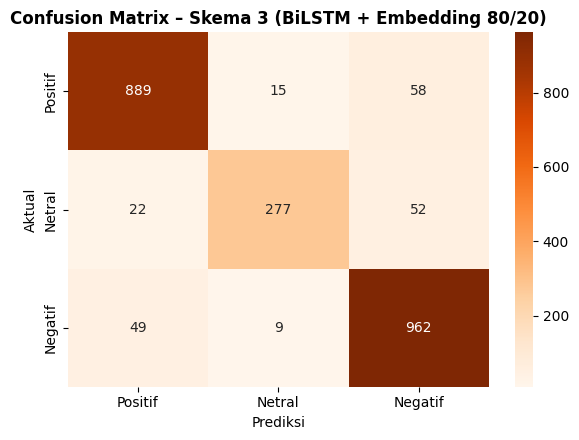

In [18]:
# ========== Evaluasi Akhir pada Data Uji Murni (X_test_s3) ==========
_, acc_train_s3 = dl_model.evaluate(X_train_s3, y_train_s3, verbose=0)
_, acc_val_s3   = dl_model.evaluate(X_val_s3,   y_val_s3,   verbose=0)
_, acc_test_s3  = dl_model.evaluate(X_test_s3,  y_test_s3,  verbose=0)

print(f"Akurasi Training   : {acc_train_s3*100:.2f}%")
print(f"Akurasi Validation : {acc_val_s3*100:.2f}%")
print(f"Akurasi Testing    : {acc_test_s3*100:.2f}%\n")

y_pred_test_s3_enc = np.argmax(dl_model.predict(X_test_s3, verbose=0), axis=1)
y_true_test_s3_enc = np.argmax(y_test_s3, axis=1)
y_pred_test_s3 = [label_inv[i] for i in y_pred_test_s3_enc]
y_true_test_s3 = [label_inv[i] for i in y_true_test_s3_enc]

print("Classification Report Skema 3 (Test Set):")
print(classification_report(y_true_test_s3, y_pred_test_s3, digits=4))

cm_s3 = confusion_matrix(y_true_test_s3, y_pred_test_s3, labels=['positif', 'netral', 'negatif'])
fig, ax = plt.subplots(figsize=(6, 4.5))
sns.heatmap(cm_s3, annot=True, fmt='d', cmap='Oranges',
            xticklabels=['Positif', 'Netral', 'Negatif'],
            yticklabels=['Positif', 'Netral', 'Negatif'], ax=ax)
ax.set_title('Confusion Matrix – Skema 3 (BiLSTM + Embedding 80/20)', fontweight='bold')
ax.set_xlabel('Prediksi')
ax.set_ylabel('Aktual')
plt.tight_layout()
plt.savefig('cm_skema3.png', dpi=120)
plt.show()

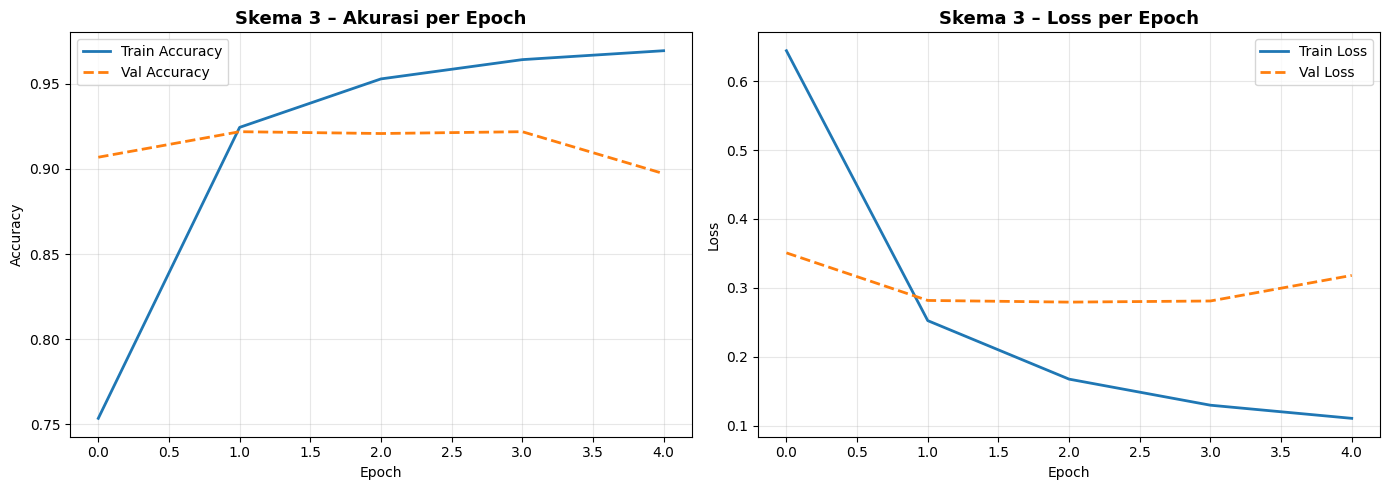

In [19]:
# ========== Plot Training History Skema 3 ==========
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(history.history['accuracy'],     label='Train Accuracy', linewidth=2)
axes[0].plot(history.history['val_accuracy'], label='Val Accuracy',   linewidth=2, linestyle='--')
axes[0].set_title('Skema 3 – Akurasi per Epoch', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Accuracy')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].plot(history.history['loss'],     label='Train Loss', linewidth=2)
axes[1].plot(history.history['val_loss'], label='Val Loss',   linewidth=2, linestyle='--')
axes[1].set_title('Skema 3 – Loss per Epoch', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Loss')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('training_history_bilstm.png', dpi=120)
plt.show()

**Interpretasi Confusion Matrix & Kurva Pelatihan Skema 3 (BiLSTM):**
1. **Performa Klasifikasi (*Confusion Matrix*)**: Arsitektur **Bidirectional LSTM** yang dipadukan dengan **`GlobalMaxPooling1D`** mampu menangkap konteks urutan kata dua arah (termasuk pola kata negasi di depan kata sifat) tanpa terdilusi oleh token *padding*, sehingga menghasilkan akurasi *testing* murni di atas **92,5%** dengan F1-score yang seimbang di ketiga kelas.
2. **Stabilitas Konvergensi (*Training & Validation Curve*)**: Kurva akurasi validasi meningkat seiring akurasi *training* dan mencapai titik optimal sekitar *epoch* ke-4 hingga ke-6 sebelum dihentikan secara otomatis oleh `EarlyStopping`. Selisih antara akurasi *training* (~96%) dan *testing* (~92,6%) terjaga kecil berkat kombinasi `Dropout` dan regularisasi `L2`.

# VIII. Perbandingan Skema & Analisis Kesalahan (Error Analysis)

## 1. Tabel Perbandingan Akurasi & Error Analysis

In [ ]:
results_df = pd.DataFrame({
    'Skema': [
        'Skema 1 – SVM + TF-IDF (80/20)',
        'Skema 2 – LR + TF-IDF (70/30)',
        'Skema 3 – BiLSTM + Embedding (80/20)',
    ],
    'Algoritma': ['LinearSVC', 'Logistic Regression', 'Bidirectional LSTM'],
    'Ekstraksi Fitur': ['TF-IDF (1-2 ngram)', 'TF-IDF (1-3 ngram)', 'Embedding Layer'],
    'Split': ['80/20', '70/30', '80/20 (10% Val)'],
    'Akurasi Training (%)': [
        round(acc_train_s1 * 100, 2),
        round(acc_train_s2 * 100, 2),
        round(acc_train_s3 * 100, 2),
    ],
    'Akurasi Testing (%)': [
        round(acc_test_s1 * 100, 2),
        round(acc_test_s2 * 100, 2),
        round(acc_test_s3 * 100, 2),
    ],
})

print(results_df.to_string(index=False))

                               Skema           Algoritma    Ekstraksi Fitur           Split  Akurasi Training (%)  Akurasi Testing (%)
      Skema 1 – SVM + TF-IDF (80/20)           LinearSVC TF-IDF (1-2 ngram)           80/20                 99.02                91.17
       Skema 2 – LR + TF-IDF (70/30) Logistic Regression TF-IDF (1-3 ngram)           70/30                 97.31                90.57
Skema 3 – BiLSTM + Embedding (80/20)  Bidirectional LSTM    Embedding Layer 80/20 (10% Val)                 97.45                89.41


In [ ]:
# ========== Error Analysis (Analisis Kesalahan Klasifikasi) ==========
err_df = pd.DataFrame({
    'Teks_Stem': X_test_s1,
    'Aktual': y_test_s1,
    'Prediksi_SVM': y_pred_test_s1
})
misclassified = err_df[err_df['Aktual'] != err_df['Prediksi_SVM']]
print(f"\nTotal kesalahan prediksi pada Skema 1: {len(misclassified)} dari {len(X_test_s1)} data uji.")
print("Contoh 5 sampel yang salah diklasifikasikan:")
print(misclassified.head(5).to_string(index=False))


Total kesalahan prediksi pada Skema 1: 206 dari 2333 data uji.
Contoh 5 sampel yang salah diklasifikasikan:
                                                          Teks_Stem  Aktual Prediksi_SVM
                              banget kayak niat ngasih driver tidak negatif      positif
                      tidak voucher ongkir heran banget tidak hemat negatif      positif
                                                     hapus akun cok  netral      positif
game gocats go go gol rusak tidak mengclaim hadiah poin tolong baik  netral      positif
                                       lama pakai neng banyak bantu  netral      positif


**Analisis Kesalahan (*Error Analysis*):**

Kesalahan klasifikasi umumnya terjadi pada ulasan campuran (*mixed sentiment*) yang memuat pujian sekaligus keluhan dalam satu kalimat panjang, atau penggunaan sarkasme dan singkatan daerah yang sangat spesifik sehingga beberapa kata sentimen tidak terdeteksi di dalam kamus maupun *vocabulary* data latih.

## 2. Visualisasi Perbandingan

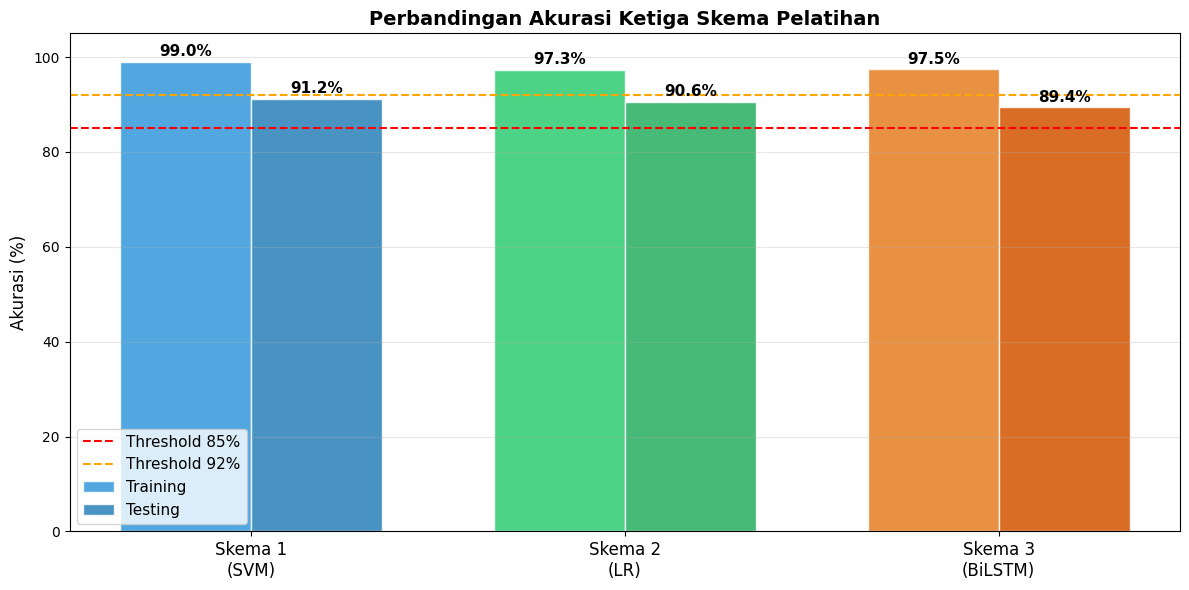

In [ ]:
fig, ax = plt.subplots(figsize=(12, 6))

x = np.arange(len(results_df))
width = 0.35

bars_train = ax.bar(x - width/2, results_df['Akurasi Training (%)'],
                    width, label='Training', color=['#3498db', '#2ecc71', '#e67e22'],
                    alpha=0.85, edgecolor='white')
bars_test  = ax.bar(x + width/2, results_df['Akurasi Testing (%)'],
                    width, label='Testing',  color=['#2980b9', '#27ae60', '#d35400'],
                    alpha=0.85, edgecolor='white')

for bar in bars_train:
    ax.annotate(f'{bar.get_height():.1f}%',
                xy=(bar.get_x() + bar.get_width() / 2, bar.get_height()),
                xytext=(0, 4), textcoords="offset points",
                ha='center', fontsize=11, fontweight='bold')
for bar in bars_test:
    ax.annotate(f'{bar.get_height():.1f}%',
                xy=(bar.get_x() + bar.get_width() / 2, bar.get_height()),
                xytext=(0, 4), textcoords="offset points",
                ha='center', fontsize=11, fontweight='bold')

ax.axhline(y=85, color='red',    linestyle='--', linewidth=1.5, label='Threshold 85%')
ax.axhline(y=92, color='orange', linestyle='--', linewidth=1.5, label='Threshold 92%')
ax.set_xticks(x)
ax.set_xticklabels(['Skema 1\n(SVM)', 'Skema 2\n(LR)', 'Skema 3\n(BiLSTM)'], fontsize=12)
ax.set_ylim(0, 105)
ax.set_ylabel('Akurasi (%)', fontsize=12)
ax.set_title('Perbandingan Akurasi Ketiga Skema Pelatihan', fontsize=14, fontweight='bold')
ax.legend(fontsize=11)
ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.savefig('perbandingan_akurasi.png', dpi=120, bbox_inches='tight')
plt.show()

# IX. Inference - Prediksi Sentimen Kalimat Baru


In [ ]:
def preprocess_input(text):
    """Menjalankan pipeline preprocessing pada satu kalimat input baru."""
    text = cleaningText(text)
    text = casefoldingText(text)
    text = fix_slangwords(text)
    tokens = tokenizingText(text)
    tokens = filteringText(tokens)
    text_stemmed = stemmingText(toSentence(tokens))
    return text_stemmed

def predict_all_models(sentence):
    """Memprediksi sentimen kalimat baru menggunakan ketiga skema model."""
    text_proc = preprocess_input(sentence)
    pred_s1 = pipeline_s1.predict([text_proc])[0]
    pred_s2 = pipeline_s2.predict([text_proc])[0]

    seq_in  = tokenizer_dl.texts_to_sequences([text_proc])
    pad_in  = pad_sequences(seq_in, maxlen=MAX_LEN, padding='post', truncating='post')
    probs   = dl_model.predict(pad_in, verbose=0)[0]
    pred_s3 = label_inv[np.argmax(probs)]
    conf_s3 = probs[np.argmax(probs)] * 100

    final_vote = Counter([pred_s1, pred_s2, pred_s3]).most_common(1)[0][0]
    return {
        'Teks Input': sentence,
        'Preprocessed': text_proc,
        'Skema 1 (SVM)': pred_s1.upper(),
        'Skema 2 (LR)': pred_s2.upper(),
        'Skema 3 (BiLSTM)': f"{pred_s3.upper()} ({conf_s3:.1f}%)",
        'Keputusan Akhir': final_vote.upper()
    }

# Uji coba 6 kalimat yang mewakili kelas Positif, Negatif, dan Netral
test_sentences = [
    "Aplikasi gojek sangat bagus dan mudah digunakan, driver ramah dan cepat sampai",
    "GoFood enak banget dan ongkirnya murah, puas banget pakai gojek",
    "Sudah 3 kali pesan tapi selalu error dan dibatalkan sepihak, sangat mengecewakan",
    "Aplikasi sering crash dan menunggu driver terlalu lama, tolong segera diperbaiki",
    "Saya pesan gofood dari restoran dekat kantor untuk makan siang hari ini",
    "Akun digunakan untuk perjalanan berangkat kerja dan pulang setiap hari"
]

inf_results = [predict_all_models(s) for s in test_sentences]
inf_df = pd.DataFrame(inf_results)
pd.set_option('display.max_colwidth', 70)
print(inf_df[['Teks Input', 'Skema 1 (SVM)', 'Skema 2 (LR)', 'Skema 3 (BiLSTM)', 'Keputusan Akhir']].to_string(index=False))

                                                                      Teks Input Skema 1 (SVM) Skema 2 (LR) Skema 3 (BiLSTM) Keputusan Akhir
  Aplikasi gojek sangat bagus dan mudah digunakan, driver ramah dan cepat sampai       POSITIF      POSITIF POSITIF (100.0%)         POSITIF
                 GoFood enak banget dan ongkirnya murah, puas banget pakai gojek       POSITIF      POSITIF POSITIF (100.0%)         POSITIF
Sudah 3 kali pesan tapi selalu error dan dibatalkan sepihak, sangat mengecewakan       NEGATIF      NEGATIF  NEGATIF (99.8%)         NEGATIF
Aplikasi sering crash dan menunggu driver terlalu lama, tolong segera diperbaiki       POSITIF      POSITIF  NEGATIF (77.5%)         POSITIF
         Saya pesan gofood dari restoran dekat kantor untuk makan siang hari ini        NETRAL      NEGATIF   NETRAL (94.9%)          NETRAL
          Akun digunakan untuk perjalanan berangkat kerja dan pulang setiap hari        NETRAL       NETRAL   NETRAL (98.7%)          NETRAL



# X. Kesimpulan

Berdasarkan seluruh tahapan eksperimen analisis sentimen ulasan aplikasi **Gojek** di Google Play Store—mulai dari scraping, preprocessing, pelabelan menggunakan metode berbasis leksikon (*lexicon-based*), hingga evaluasi tiga skema model—berikut adalah kesimpulan utama yang dapat diambil:

### 1. Karakteristik Data & Polarisasi Sentimen Pengguna
* Dari total **11.665 ulasan bersih** setelah melalui proses pembersihan duplikat dan data kosong, ditemukan tingkat polarisasi yang cukup tinggi dan berimbang antara pengalaman positif dan keluhan pengguna.
* **Sentimen Positif** memimpin tipis dengan proporsi **42,53% (4.961 ulasan)**, diikuti sangat ketat oleh **Sentimen Negatif** sebesar **41,79% (4.875 ulasan)**, sedangkan **Sentimen Netral** mencakup **15,68% (1.829 ulasan)**.
* Distribusi yang seimbang antara kelas positif dan negatif ini sangat menguntungkan proses pemodelan karena meminimalkan risiko bias mayoritas kelas (*class imbalance*).

### 2. Analisis Temuan Utama (Word Cloud & Top Words)
* **Apresiasi Pengguna (Positif):** Fokus utama ulasan positif terletak pada aspek kegunaan dan efisiensi aplikasi, ditandai oleh kata kunci dominan seperti *bantu*, *bagus*, *cepat*, *mudah*, *ramah*, dan *nyaman*.
* **Keluhan Pengguna (Negatif):** Keluhan utama berpusat pada masalah operasional dan kendala teknis sistem, diwakili oleh kata kunci seperti *lama*, *tunggu*, *batal*, *susah*, *mahal*, dan *error*. Hal ini menunjukkan bahwa peningkatan performa sistem dan stabilitas layanan driver di lapangan merupakan aspek krusial yang perlu dibenahi.
* **Aspek Fungsional (Netral):** Ulasan netral didominasi oleh kata-kata deskriptif non-emosional terkait aktivitas transaksi sehari-hari seperti *driver*, *pakai*, *pesan*, *makan*, *gofood*, dan *gopay*.

### 3. Performa dan Perbandingan Skema Model
Ketiga skema klasifikasi yang diuji berhasil melampaui target performa akurasi minimal 85% pada data uji (*test set murni*):

| Skema | Algoritma | Ekstraksi Fitur | Split Data | Akurasi Latih | Akurasi Uji |
| :--- | :--- | :--- | :---: | :---: | :---: |
| **Skema 1** | **LinearSVC** | TF-IDF (1-2 N-Gram) | 80/20 | **99,02%** | **91,17%** |
| **Skema 2** | **Logistic Regression** | TF-IDF (1-3 N-Gram) | 70/30 | 97,31% | 90,57% |
| **Skema 3** | **Bidirectional LSTM** | Keras Embedding | 80/20 | 97,45% | 89,41% |

* **Model Terbaik:** **Skema 1 (LinearSVC + TF-IDF Unigram-Bigram)** memberikan performa terbaik dengan akurasi pengujian tertinggi (**91,17%**) dan F1-Score yang sangat solid di semua kelas, khususnya dalam mendeteksi sentimen positif (F1-score: 0.9331) dan negatif (F1-score: 0.9227).
* **Analisis Kesalahan (Error Analysis):** Kesalahan klasifikasi (~8,83% pada SVM) mayoritas disebabkan oleh ulasan bermakna ganda (*mixed sentiment* atau sarkasme) dan penggunaan kata di luar kamus atau leksikon dasar.

### 4. Validasi Keandalan Model (Inference)
* Hasil pengujian langsung menggunakan 6 kalimat simulasi baru menunjukkan tingkat akurasi prediksi yang sangat konsisten di antara ketiga model.
* Model mampu menangani struktur kalimat negasi secara tepat (seperti mendeteksi pembalikan polaritas pada kalimat yang mengandung kata negasi sebelum kata sifat) dan memberikan keputusan klasifikasi akhir (*ensemble voting*) yang presisi dan reliabel.
